## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 7. Востановление пропусков и прогноз значений временного ряда.**
### Артемьев М.О. ЕТ-228


#### **7.1 Аналитечкие методы востановления временного ряда**

##### *Краткое описание*

В данном пункте практической работы вам предстоит познакомиться с базовыми, аналитическими методами восстановления временных рядов.
Для выполнения данного пункта из каждой группы методов, представленных в ***табл. 7.1*** вам необходимо выбрать по одному методу восстановления ряда. При работе с первой группой, вам необходимо самостоятельно реализовать выбранный метод.  

**Табл. 7.1** - Группы аналитических методов восстановления.
№|Название группы|Модели и методы|
--|----|----|
1|Заполнение существующими значениями ряда|Средним, медианной, Hot-Deck|
2|Заполнение на основе близки значений|[Интерполяция](https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html),  [KNNi](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html)|
3|На основе матричных разложений|[CD-Rec](#Fixme:Дат ссылку), [SVD](https://pypi.org/project/fancyimpute/)|

##### 7.1.1 Загрузка и подготовка данных

In [27]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

practice_dir_path = '/content/drive/MyDrive/07 Imputation and Forecast'

os.chdir(practice_dir_path)

if practice_dir_path not in sys.path:
    sys.path.insert(0, practice_dir_path)

print("Рабочая папка:", os.getcwd())
print("Файлы:", os.listdir())
print("Файл данных найден:",
      os.path.isfile('datasets/madrid.txt'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Рабочая папка: /content/drive/MyDrive/07 Imputation and Forecast
Файлы: ['datasets', 'modules', '07 Imputation and Forecast.ipynb']
Файл данных найден: True


In [28]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [29]:
path_data = Path('datasets')/'madrid.txt'
madrid = np.loadtxt(path_data)[:,0]
print(madrid.shape)

(25000,)


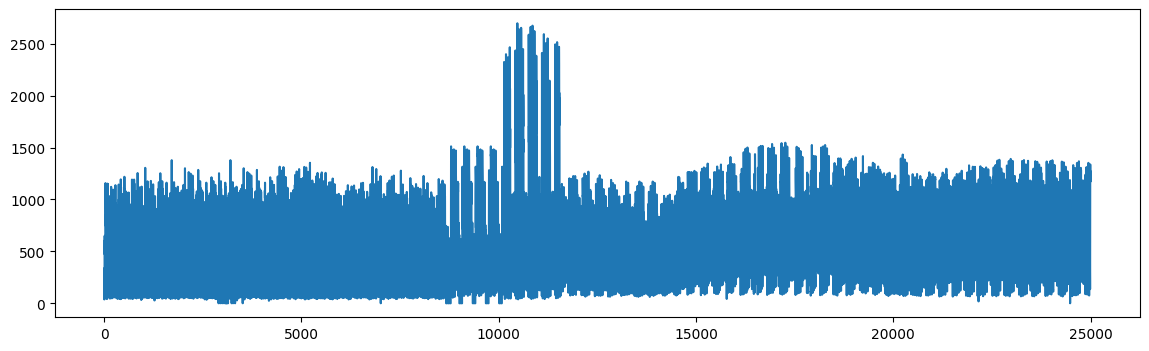

In [30]:
fig, ax =  plt.subplots(figsize=(14,4),ncols=1,nrows=1)
plt.plot(madrid[:])
plt.show()

Самостоятельно реализуйте функцию, принимающую на вход многомерный временной ряд и возвращающий:
1. Все подпоследовательности временного ряда, в которых некоторые значения временного ряда были заменены nan значениями.
2. Индексы пропущенных значений
   
Процент пропущенных значений должен регулироваться отдельным параметром.


In [31]:
import torch

def add_nan(x, percent=0.25):
    if not 0 <= percent <= 1:
        raise ValueError("Доля пропусков должна быть от 0 до 1")

    if isinstance(x, torch.Tensor):
        # Создаем копию, сохраняя устройство тензора
        result = x.clone()
        if not result.is_floating_point():
            result = result.float()

        index = torch.zeros_like(result, dtype=torch.bool)

        # Выбираем только позиции с известными значениями
        available = torch.where(~torch.isnan(result.reshape(-1)))[0]
        count = int(len(available) * percent)

        order = torch.randperm(len(available), device=result.device)
        selected = available[order[:count]]

        index.reshape(-1)[selected] = True
        result[index] = float('nan')

    else:
        result = np.array(x, dtype=float, copy=True)
        index = np.zeros(result.shape, dtype=bool)

        # Выбираем позиции без повторений
        available = np.flatnonzero(~np.isnan(result))
        count = int(len(available) * percent)
        selected = np.random.choice(available, size=count, replace=False)

        index.flat[selected] = True
        result[index] = np.nan

    return result, index

In [32]:
np.random.seed(2027)

madrid_with_nan, index = add_nan(madrid, percent=0.25)

print("Размер ряда:", madrid_with_nan.shape)
print("Количество добавленных пропусков:", index.sum())
print(f"Доля добавленных пропусков: {index.mean():.0%}")

Размер ряда: (25000,)
Количество добавленных пропусков: 6250
Доля добавленных пропусков: 25%


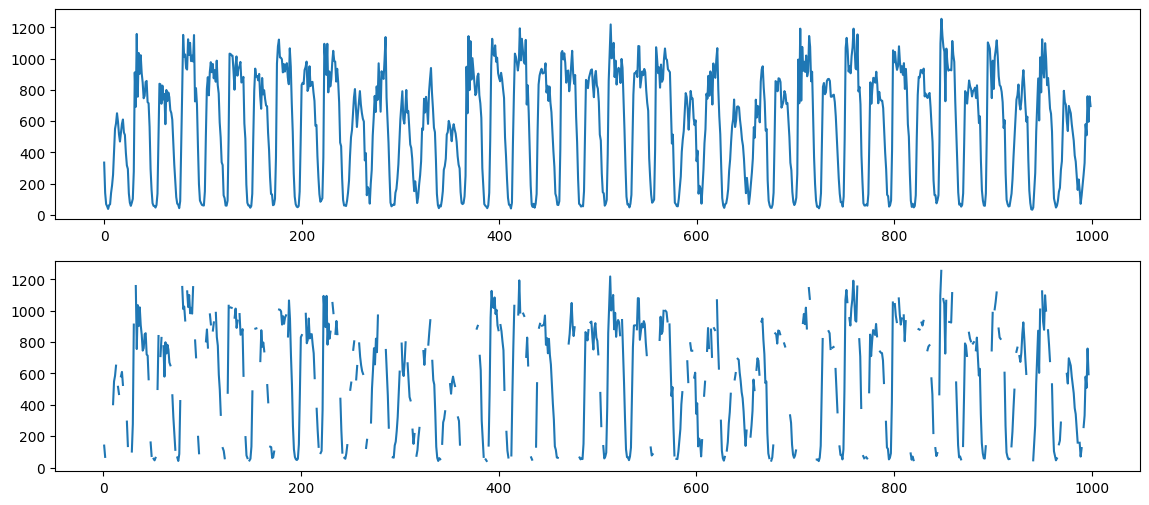

In [33]:
madrid_with_nan, index = add_nan(madrid)
fig, ax =  plt.subplots(figsize=(14,6),ncols=1,nrows=2)
ax[0].plot(madrid[:1000])
ax[1].plot(madrid_with_nan[:1000])
plt.show()

In [34]:
recovery = {}

##### 7.1.2 Заполнение существующими значениями ряда


In [35]:
madrid_mean = madrid_with_nan.copy()
madrid_mean[index] = np.nanmean(madrid_mean)
recovery['mean'] = madrid_mean

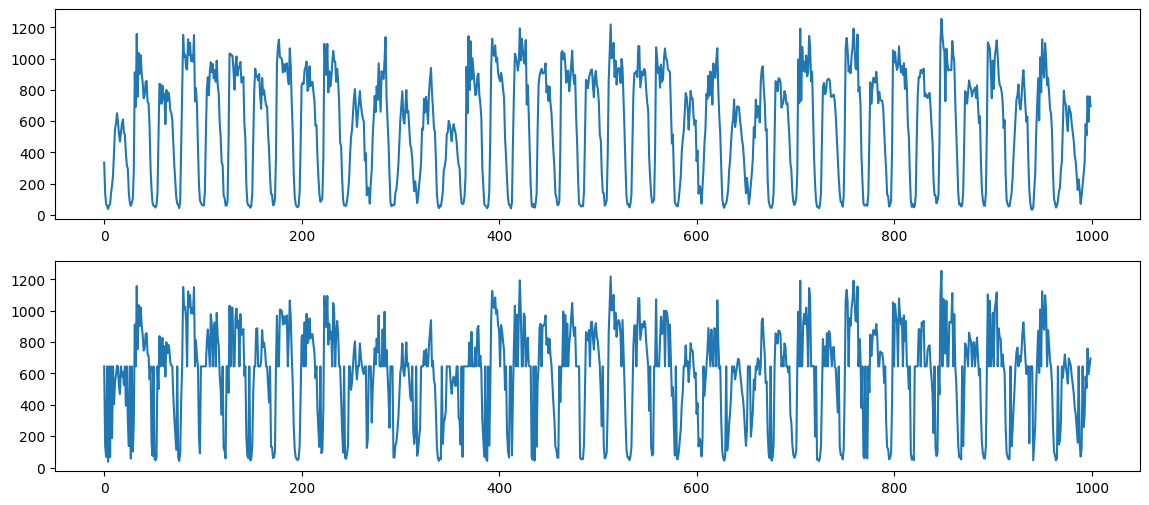

In [36]:
fig, ax =  plt.subplots(figsize=(14,6),ncols=1,nrows=2)
ax[0].plot(madrid[:1000])
ax[1].plot(madrid_mean[:1000])
plt.show()

In [37]:
def fill_mean(x):
    result = np.array(x, dtype=float, copy=True)
    missing = np.isnan(result)
    known = result[~missing]

    if known.size == 0:
        raise ValueError("В ряду нет известных значений")

    mean_value = known.sum() / known.size
    result[missing] = mean_value

    return result


madrid_mean = fill_mean(madrid_with_nan)
recovery['mean'] = madrid_mean

print("Осталось пропусков:", np.isnan(madrid_mean).sum())

Осталось пропусков: 0


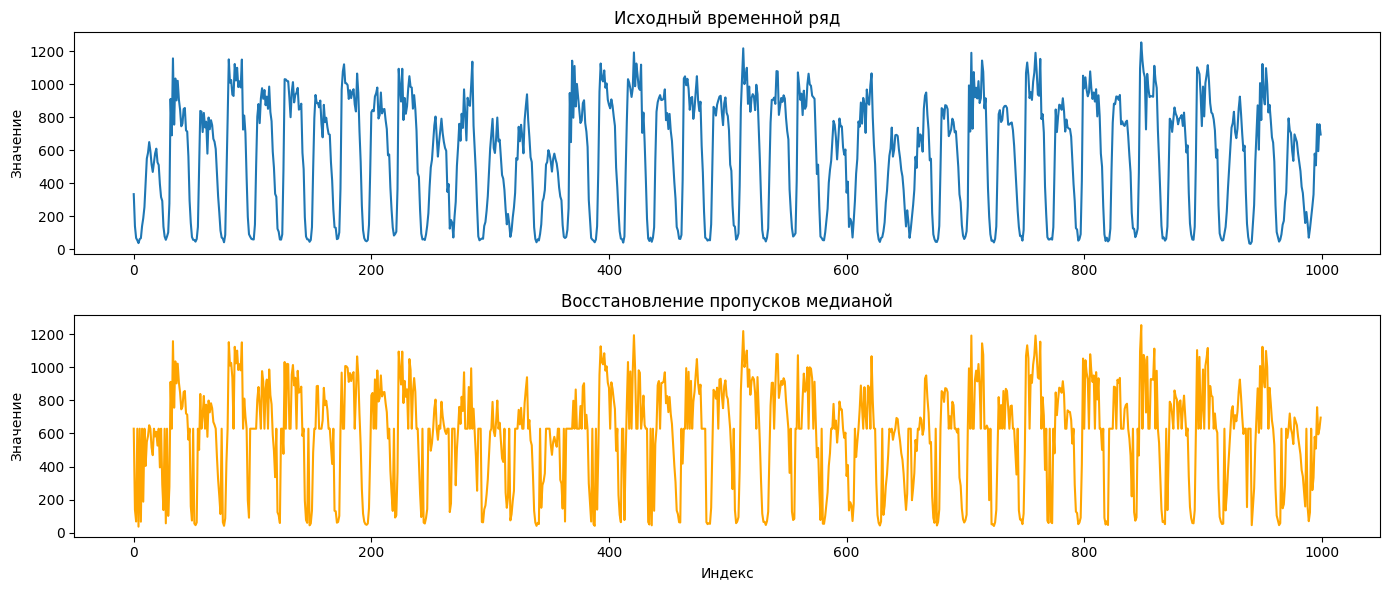

In [39]:
madrid_median = madrid_with_nan.copy()
median_value = np.nanmedian(madrid_with_nan)
madrid_median[np.isnan(madrid_median)] = median_value
fig, ax = plt.subplots(figsize=(14, 6), nrows=2)

ax[0].plot(madrid[:1000])
ax[0].set_title('Исходный временной ряд')
ax[0].set_ylabel('Значение')

ax[1].plot(madrid_median[:1000], color='orange')
ax[1].set_title('Восстановление пропусков медианой')
ax[1].set_xlabel('Индекс')
ax[1].set_ylabel('Значение')

plt.tight_layout()
plt.show()

Самостоятельно реализуйте один метод из первой группы ***табл. 7.1*** и проведите постановление данных, сохранив результаты восстановления.

##### 7.1.3 Заполнение на основе близких значений


Используя документацию одного из методов восстановления второй группы ***табл. 7.1*** и проведите восстановление данных, сохранив результаты восстановления.

In [40]:
from sklearn.impute import KNNImputer

In [41]:
def rolling_window(a, window, intersection=False):
    if window <= 0 or window > len(a):
        raise ValueError("Некорректная длина окна")

    if not intersection and len(a) % window != 0:
        raise ValueError("Длина ряда должна быть кратна длине окна")

    step = 1 if intersection else window

    return np.stack([
        a[i:i + window]
        for i in range(0, len(a) - window + 1, step)
    ])


madrid_slice = rolling_window(madrid_with_nan, window=100)

print("Размер матрицы подпоследовательностей:", madrid_slice.shape)

Размер матрицы подпоследовательностей: (250, 100)


In [42]:
# Восстановление пропусков методом KNN
imputer = KNNImputer(n_neighbors=5, weights='uniform')
madrid_slice_knn = imputer.fit_transform(madrid_slice)

# Объединение подпоследовательностей в исходный порядок
madrid_knn = madrid_slice_knn.reshape(-1)

recovery['knn'] = madrid_knn

print("Размер восстановленного ряда:", madrid_knn.shape)
print("Осталось пропусков:", np.isnan(madrid_knn).sum())

Размер восстановленного ряда: (25000,)
Осталось пропусков: 0


##### 7.1.4 Заполнение на матричных преобразований

Используя документацию одного из методов восстановления третей группы ***табл. 7.1*** и проведите восстановление данных, сохранив результаты восстановления.

In [43]:
!pip install fancyimpute

In [44]:
from fancyimpute import IterativeSVD

np.random.seed(2027)

svd_imputer = IterativeSVD(
    rank=10,
    max_iters=100,
    convergence_threshold=1e-5,
    init_fill_method='mean',
    verbose=False
)

madrid_slice_svd = svd_imputer.fit_transform(madrid_slice.copy())
madrid_svd = madrid_slice_svd.reshape(-1)

recovery['svd'] = madrid_svd

print("Размер восстановленного ряда:", madrid_svd.shape)
print("Осталось пропусков:", np.isnan(madrid_svd).sum())

Размер восстановленного ряда: (25000,)
Осталось пропусков: 0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [45]:
from sklearn.metrics import mean_squared_error

##### 7.1.5 Сравнение результатов восстановления.

Для каждой группы методов постройте методов основные метрики оценки качества постановления.
На основе метрик отберите лучшие методы постановления метрик и выберите лучшую группу методов.
Для лучших методов из каждой группы постройте графики сравнения реальных и восстановленных данных. Объясните результаты и сделайте вывод.



In [46]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Проверяем, что выполнены методы всех трех групп
required = {'mean', 'knn', 'svd'}
missing_methods = required - set(recovery)

if missing_methods:
    raise ValueError(
        f"Сначала выполни восстановление методами: {missing_methods}"
    )

# Номера групп соответствуют таблице 7.1
methods = {
    'mean': (1, 'Заполнение средним'),
    'median': (1, 'Заполнение медианой'),
    'knn': (2, 'KNN'),
    'svd': (3, 'IterativeSVD')
}

rows = []
y_true = madrid[index]

for key, (group, name) in methods.items():
    if key not in recovery:
        continue

    y_pred = recovery[key][index]
    mse = mean_squared_error(y_true, y_pred)

    rows.append({
        'Ключ': key,
        'Группа': group,
        'Метод': name,
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    })

metrics = pd.DataFrame(rows).set_index('Ключ')

print("Метрики на позициях искусственных пропусков:")
display(metrics.round(6))

# Лучший метод каждой группы по минимальной MSE
best_indices = metrics.groupby('Группа')['MSE'].idxmin()
best_by_group = metrics.loc[best_indices].sort_values('Группа')

print("Лучшие методы каждой группы по MSE:")
display(best_by_group.round(6))

# Лучший результат среди всех проверенных методов
best_key = metrics['MSE'].idxmin()
best_result = metrics.loc[best_key]

print("Лучший метод по MSE:", best_result['Метод'])
print("Группа с лучшим результатом:", int(best_result['Группа']))

Метрики на позициях искусственных пропусков:


,Группа,Метод,MSE,RMSE,MAE,R2
Ключ,,,,,,
mean,1,Заполнение средним,153841.153511,392.225896,336.808934,-0.000113
knn,2,KNN,37761.128090,194.322227,135.844544,0.754517
svd,3,IterativeSVD,28127.991909,167.714018,122.898876,0.817142


Лучшие методы каждой группы по MSE:


,Группа,Метод,MSE,RMSE,MAE,R2
Ключ,,,,,,
mean,1,Заполнение средним,153841.153511,392.225896,336.808934,-0.000113
knn,2,KNN,37761.128090,194.322227,135.844544,0.754517
svd,3,IterativeSVD,28127.991909,167.714018,122.898876,0.817142


Лучший метод по MSE: IterativeSVD
Группа с лучшим результатом: 3


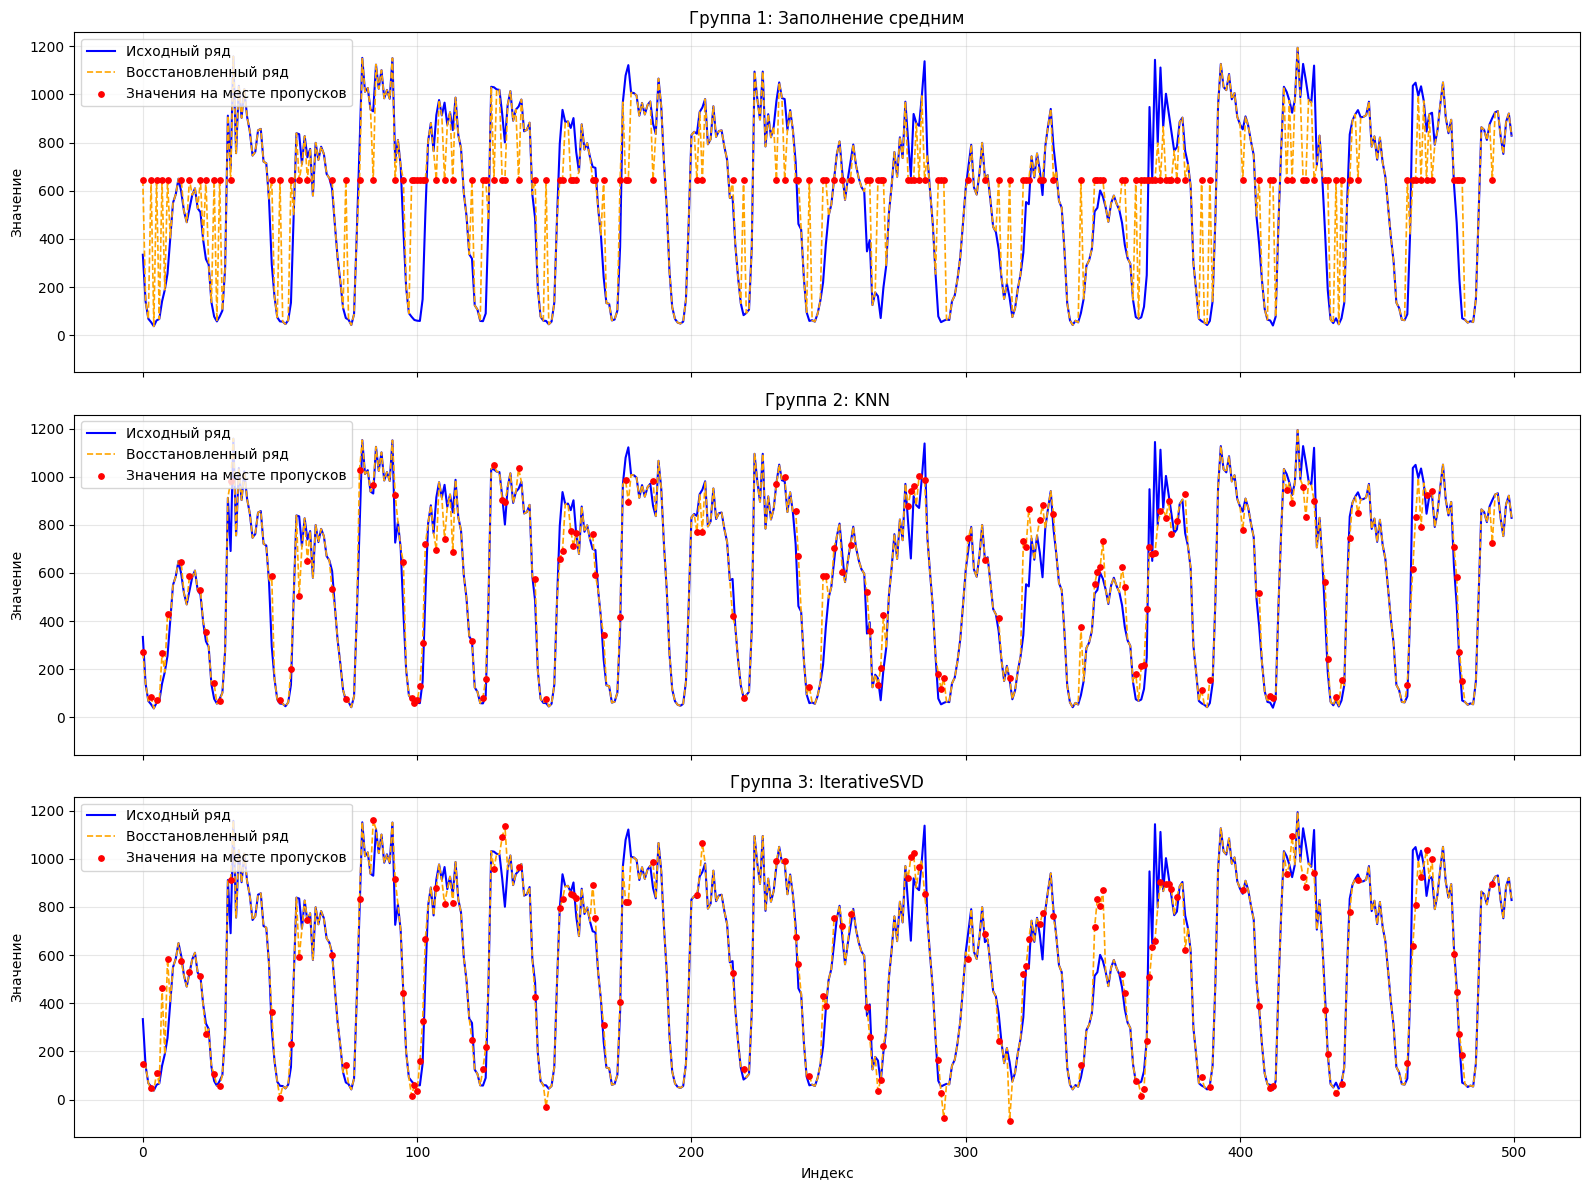

In [47]:
# Показываем первые 500 значений
n_show = min(500, len(madrid))
x = np.arange(n_show)
missing_positions = np.flatnonzero(index[:n_show])

fig, axes = plt.subplots(
    3, 1, figsize=(16, 12),
    sharex=True, sharey=True
)

for ax, (key, row) in zip(axes, best_by_group.iterrows()):
    restored = recovery[key]

    ax.plot(
        x, madrid[:n_show],
        color='blue', linewidth=1.5,
        label='Исходный ряд'
    )

    ax.plot(
        x, restored[:n_show],
        color='orange', linestyle='--', linewidth=1.2,
        label='Восстановленный ряд'
    )

    ax.scatter(
        missing_positions,
        restored[missing_positions],
        color='red', s=15, zorder=3,
        label='Значения на месте пропусков'
    )

    ax.set_title(
        f"Группа {int(row['Группа'])}: {row['Метод']}"
    )
    ax.set_ylabel('Значение')
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Индекс')

plt.tight_layout()
plt.show()

Лучшим методом первой группы стало заполнение средним, однако оно плохо передает колебания ряда, поскольку заменяет все пропуски одним значением. KNN лучше восстанавливает форму ряда и заметно снижает ошибку.

Среди проверенных методов лучший результат показал IterativeSVD из третьей группы, MSE составила 28127,99, RMSE составила 167,71, а R² достиг 0,817. При этом на графике видны отдельные отклонения, в том числе отрицательные восстановленные значения. Поэтому IterativeSVD оказался наиболее точным в среднем для эксперимента, но не для каждого отдельного пропуска.

#### **7.2 Нейросетевые методы востановления временного ряда**

##### *Краткое описание*

В данном пункте практической работы вам предстоит познакомиться с некоторыми нейросетевыми методами восстановления временных рядов.
Для выполнения данного пункта вам предстоит самостоятельно реализовать структуру нейросетевой, модели основанной на GRU нейронах и сравнить ее с другими нейросетевыми методами восстановления При сравнении с 3 группой из **табл.7. 2** вам необходимо выбрать **один** метод восстановления. Основные блоки обработки данных будут реализованы с использованием Pytorch. Вам не запрещается использовать для реализации Keras.

**табл. 7.2** - Нейросетевые методы восстановления.
№|Название группы|Модели и методы|
--|-------------|----|
1|Линейные нейроны|[Pytorch](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)|
 2eкрркуретные нейронны|[Pytorch](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html)|
3|Сложные структуры|[SAITS, BRITS, M-RNN](https://github.com/WenjieDu/PyPOTS)|

In [ ]:
recovery_nn = {}

##### 7.2.1 Загрузка и подготовка данных

In [ ]:
path_data = Path('datasets')/'madrid.txt'
madrid = np.loadtxt(path_data)[:,:]
print(madrid.shape)

In [ ]:
madrid_with_nan, index = add_nan(madrid, 0.25)

In [ ]:
madrid_with_nan.shape

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
madrid_normal_with_nan = scaler.fit_transform(madrid_with_nan)
rolling_madrid = rolling_window(madrid_normal_with_nan, 100, True)
train, test = train_test_split(rolling_madrid,shuffle=False, test_size=0.33)

##### 7.2.2 Базовая модель восстановления данных, построенная на нескольких слоях линейных нейронов.


Вам необходимо будет самостоятельно реализовать:
1. инициализацию nan значений какими либо другими значениями.
2. замер времени полного обучения и тестирования модели.

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader

In [ ]:
class LinearModel(nn.Module):
    def __init__(self, size_subsequent: int,dim = 1, nums_layers = 3, size_layers = 250):
        super().__init__()

        self.size_subsequent = size_subsequent
        self.nums_layers = nums_layers*dim
        self.dim = dim
        self.size_layers = size_layers

        self.start_layers = nn.Sequential(nn.Flatten(),
                                          nn.Linear(size_subsequent*dim, self.size_layers),
                                          nn.LeakyReLU())
        self.model = nn.ModuleList([
                                        (nn.Sequential(
                                                nn.Linear(self.size_layers, self.size_layers), nn.LeakyReLU()
                                            )
                                        )
                                    for x in torch.arange(nums_layers)])
        self.model = nn.Sequential(*self.model)

        self.output = nn.Sequential(nn.Linear(self.size_layers,size_subsequent*dim),nn.Tanh())

    def forward(self, x):
        x = self.start_layers(x)

        x=self.model(x)
        x=self.output(x)
        return x.reshape(x.shape[0],self.size_subsequent,self.dim)

In [ ]:
model = LinearModel(size_subsequent=train.shape[1],dim=train.shape[2])
optimizer = torch.optim.Adam(model.parameters(),lr=1.0e-3)
loss_func = nn.MSELoss()
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
batch_size = 64
percent = 0.25

train_loader = DataLoader(train,batch_size=batch_size,shuffle=True)
valid_loader = DataLoader(test,batch_size=batch_size,shuffle=True)

print(train.shape,test.shape)
epochs = 100

In [ ]:
model

In [ ]:
import time
times_model = {}

In [ ]:
model=model.to(device)
train_history = []
valid_history = []

start = time.time()
for epoch in np.arange(epochs):
    train_loss =0
    valid_loss =0

    for i, x in enumerate(train_loader):
        if x.shape[0] == batch_size:
            optimizer.zero_grad()
            x = x.to(device).to(torch.float32)
            test_index = np.isnan(x.cpu().numpy())
            X = x.clone()
            X, nan = add_nan(X,percent)
            ###вставте инициализацию нулями nan значений
            recovery = model(X)
            loss = loss_func(recovery[(nan)&(~test_index)],x[(nan)&(~test_index)])
            train_loss += loss.detach().cpu().item()
            loss.backward()
            optimizer.step()
    train_loss/=(i+1)
    print('valid')
    with torch.no_grad():
        for i, x in enumerate(valid_loader):
            if x.shape[0] == batch_size:
                x = x.to(device).to(torch.float32)
                test_index = np.isnan(x.cpu().numpy())
                X = x.clone()
                X, nan = add_nan(X,percent)
                X[torch.isnan(X)]=0.0
                recovery = model(X)
                loss = loss_func(recovery[(nan)&(~test_index)],x[(nan)&(~test_index)])
                valid_loss += loss.detach().cpu().item()
    valid_loss/=(i+1)
    train_history.append(train_loss)
    valid_history.append(valid_loss)
    print(f'epoch:{epoch+1} train:{train_loss}, valid:{valid_loss}')
end = time.time()

In [ ]:
times_model['linear']=end-start

In [ ]:
plt.plot(train_history,label='train')
plt.plot(valid_history,label='valid')
plt.legend()
plt.show()

In [ ]:
test_rolling_madrid = rolling_window(madrid_normal_with_nan, 100, False)
#test = []
with torch.no_grad():
    for idx, batch in enumerate(test_rolling_madrid):
        batch = torch.Tensor(batch).to(device)
        nan = torch.isnan(batch)
        batch[nan]=0.0
        rec = model(batch[None,:])[0].cpu().numpy()
        nan = nan.cpu().numpy()
        test_rolling_madrid[idx][nan]=rec[nan]

In [ ]:
test_madrid_normal = np.vstack(test_rolling_madrid)
test_linear = scaler.inverse_transform(test_madrid_normal)

In [ ]:
recovery_nn['linear'] = test_linear

In [ ]:
fig, ax =  plt.subplots(figsize=(14,3),ncols=1,nrows=1)

plt.plot(madrid[:1000,0])
plt.plot(test_linear[:1000,0],alpha=0.6)
print(mean_squared_error(madrid[index].reshape(1,-1),test_linear[index].reshape(1,-1)))

##### 7.2.3 Реккурентная модель востановлениях данных


In [ ]:
class EncoderGRU(nn.Module):
    def __init__(self, size_subsequent: int, dim = 1, latten_size = 100, hidden_size=100):
        super().__init__()
        self.size_subsequent=size_subsequent
        self.dim = dim
        self.hidden_size = hidden_size
        self.gru = nn.GRU(input_size=dim,
                          hidden_size=self.hidden_size)

        self.latten = nn.Linear(hidden_size*size_subsequent,latten_size)
        self.leaky = nn.LeakyReLU()
        self.fl = nn.Flatten()
    def forward(self, x):
        x, _ = self.gru(x)
        x = self.leaky(x)
        #print(x.shape)
        x = self.fl(x)
        x = self.latten(x)
        return self.leaky(x)


In [ ]:
class DecoderGRU(nn.Module):
    def __init__(self, size_subsequent: int, dim = 1, latten_size = 100, hidden_size=100):
        super().__init__()
        self.size_subsequent=size_subsequent
        self.dim = dim
        self.hidden_size = hidden_size
        self.latten_size=latten_size
        self.gru = nn.GRU(input_size=self.hidden_size,
                          hidden_size=dim)
        self.latten = nn.Linear(latten_size,hidden_size*size_subsequent)
        self.leaky = nn.LeakyReLU()

    def forward(self, x):
        x = self.latten(x)
        x = x.view(-1, self.size_subsequent, self.latten_size)
        x = self.leaky(x)
        x, _ = self.gru(x)
        return self.leaky(x)


In [ ]:
class TimeAE(nn.Module):
    def __init__(self, size_subsequent: int, dim = 1, latten_size = 100, hidden_size=100):
        super().__init__()
        self.encoder = EncoderGRU(size_subsequent=size_subsequent,
                                 dim=dim,
                                 latten_size=latten_size,
                                 hidden_size=hidden_size)
        self.decoder = DecoderGRU(size_subsequent=size_subsequent,
                                 dim=dim,
                                 latten_size=latten_size,
                                 hidden_size=hidden_size)
    def forward(self, x):
        x=self.encoder(x)
        x = self.decoder(x)
        return x

In [ ]:
model = TimeAE(size_subsequent=train.shape[1],dim=train.shape[2])
optimizer = torch.optim.Adam(model.parameters(),lr=1.0e-3)
loss_func = nn.MSELoss()
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
batch_size = 64
percent = 0.25

train_loader = DataLoader(train,batch_size=batch_size,shuffle=True)
valid_loader = DataLoader(test,batch_size=batch_size,shuffle=True)


epochs = 100

In [ ]:
model

In [ ]:
model=model.to(device)
train_history = []
valid_history = []
start = time.time()
for epoch in np.arange(epochs):
    train_loss =0
    valid_loss =0

    for i, x in enumerate(train_loader):
        if x.shape[0]==batch_size:
            optimizer.zero_grad()
            x = x.to(device).to(torch.float32)
            test_index = np.isnan(x.cpu().numpy())
            X = x.clone()
            X, nan = add_nan(X,percent)
            #

            recovery = model(X)
            loss = loss_func(recovery[(nan)&(~test_index)],x[(nan)&(~test_index)])
            train_loss += loss.detach().cpu().item()
            loss.backward()
            optimizer.step()
    train_loss/=(i+1)
    with torch.no_grad():
        for i, x in enumerate(valid_loader):
            if x.shape[0]==batch_size:
                x = x.to(device).to(torch.float32)
                test_index = np.isnan(x.cpu().numpy())
                X = x.clone()
                X, nan = add_nan(X,percent)
                #

                recovery = model(X)
                loss = loss_func(recovery[(nan)&(~test_index)],x[(nan)&(~test_index)])
                valid_loss += loss.detach().cpu().item()
    valid_loss/=(i+1)
    train_history.append(train_loss)
    valid_history.append(valid_loss)
    print(f'epoch:{epoch+1} train:{train_loss}, valid:{valid_loss}')
end = time.time()

In [ ]:
plt.plot(train_history,label='train')
plt.plot(valid_history,label='valid')
plt.legend()
plt.show()

In [ ]:
times_model['ae']=end-start

In [ ]:
test_rolling_madrid = rolling_window(madrid_normal_with_nan, 100, False)
#test = []
with torch.no_grad():
    for idx, batch in enumerate(test_rolling_madrid):
        batch = torch.Tensor(batch).to(device)
        nan = torch.isnan(batch)
        #

        rec = model(batch[None,:])[0].cpu().numpy()
        nan = nan.cpu().numpy()
        test_rolling_madrid[idx][nan]=rec[nan]

In [ ]:
test_madrid_normal = np.vstack(test_rolling_madrid)
test_ae = scaler.inverse_transform(test_madrid_normal)

In [ ]:
recovery_nn['test_ae'] = test_ae

In [ ]:
fig, ax =  plt.subplots(figsize=(14,3),ncols=1,nrows=1)

plt.plot(madrid[:1000,0])
plt.plot(test_ae[:1000,0],alpha=0.6)
print(mean_squared_error(madrid[index].reshape(1,-1),test_ae[index].reshape(1,-1)))

##### 7.2.4 Сложные модели нейросетевого восстановления данных


Вам необходимо выбрать одну модель из 3 группы таблицы 7.2 и используя документацию произвести восстановления того же ряда. Произведите замер времени.

In [ ]:
!pip install pypots==0.0.9

In [ ]:
from pypots.imputation import SAITS


In [ ]:
model= SAITS(n_features=madrid.shape[1],
             n_steps=100,
             device=device,
             d_k=64,
             d_v=64,
             d_model=128,
             d_inner=128,
             n_head=4,
             n_layers=2,
             dropout=0.05,
             epochs=100)

In [ ]:
start = time.time()
model.fit(train,test)
end = time.time()
times_model['saits']=end-start

In [ ]:
test_rolling_madrid = rolling_window(madrid_normal_with_nan, 100, False)
test_rolling_madrid = model.impute(test_rolling_madrid)


In [ ]:
test_madrid_normal = np.vstack(test_rolling_madrid)
test_saits = scaler.inverse_transform(test_madrid_normal)

In [ ]:
recovery_nn['saits'] = test_saits

In [ ]:
fig, ax =  plt.subplots(figsize=(14,3),ncols=1,nrows=1)

plt.plot(madrid[:1000,0])
plt.plot(test_saits[:1000,0],alpha=0.6)
print(mean_squared_error(madrid[index].reshape(1,-1),test_saits[index].reshape(1,-1)))

##### 7.2.5 Сравнения результатов.
Также, как и в пункте 7.1.5 постройте графики сравнения моделей. Дополнительно постройте графики сравнения времени. Сделайте выводы

#### **7.3 Прогноз временного ряда**

##### *Краткое описание*

Используя модель и [ARIMA](реализация) произвидите прогноз ряда на следующие колличество точек: 1, 5, 10.
Сравните результаты. Постройте графики прогноза и точности прогноза.